In [1]:
import re
import pandas as pd

In [2]:
data = {
    "English": [
        "hello",
        "good morning",
        "good night",
        "how are you",
        "i am fine",
        "thank you",
        "what is your name",
        "my name is amit",
        "i love india",
        "where are you going",
        "please help me",
        "i am learning python",
        "this is a book",
        "the weather is good",
        "see you tomorrow"
    ],
    "Hindi": [
        "नमस्ते",
        "सुप्रभात",
        "शुभ रात्रि",
        "आप कैसे हैं",
        "मैं ठीक हूँ",
        "धन्यवाद",
        "आपका नाम क्या है",
        "मेरा नाम अमित है",
        "मुझे भारत से प्यार है",
        "आप कहाँ जा रहे हैं",
        "कृपया मेरी मदद करें",
        "मैं पाइथन सीख रहा हूँ",
        "यह एक किताब है",
        "मौसम अच्छा है",
        "कल मिलते हैं"
    ]
}

df = pd.DataFrame(data)
display(df)

,English,Hindi
0,hello,नमस्ते
1,good morning,सुप्रभात
2,good night,शुभ रात्रि
3,how are you,आप कैसे हैं
4,i am fine,मैं ठीक हूँ
5,thank you,धन्यवाद
6,what is your name,आपका नाम क्या है
7,my name is amit,मेरा नाम अमित है
8,i love india,मुझे भारत से प्यार है
9,where are you going,आप कहाँ जा रहे हैं


In [3]:
def preprocess_english(text):
    text = text.lower().strip()
    text = re.sub(r"[^\w\s]", "", text)
    text = re.sub(r"\s+", " ", text)
    return text

df["English_Clean"] = df["English"].apply(preprocess_english)

display(df[["English", "English_Clean"]].head())

,English,English_Clean
0,hello,hello
1,good morning,good morning
2,good night,good night
3,how are you,how are you
4,i am fine,i am fine


In [4]:
translation_dict = dict(zip(df["English_Clean"], df["Hindi"]))

print("Total sentence pairs:", len(translation_dict))
print("\nSample dictionary entries:")

for english, hindi in list(translation_dict.items())[:5]:
    print(f"{english} -> {hindi}")

Total sentence pairs: 15

Sample dictionary entries:
hello -> नमस्ते
good morning -> सुप्रभात
good night -> शुभ रात्रि
how are you -> आप कैसे हैं
i am fine -> मैं ठीक हूँ


In [5]:
def translate_to_hindi(sentence):
    cleaned_sentence = preprocess_english(sentence)

    if cleaned_sentence in translation_dict:
        return translation_dict[cleaned_sentence]

    return "Translation not available in the sample dataset."

print(translate_to_hindi("hello"))
print(translate_to_hindi("how are you"))
print(translate_to_hindi("i love india"))

नमस्ते
आप कैसे हैं
मुझे भारत से प्यार है


In [6]:
df["Predicted_Hindi"] = df["English"].apply(translate_to_hindi)

display(df[["English", "Hindi", "Predicted_Hindi"]])

,English,Hindi,Predicted_Hindi
0,hello,नमस्ते,नमस्ते
1,good morning,सुप्रभात,सुप्रभात
2,good night,शुभ रात्रि,शुभ रात्रि
3,how are you,आप कैसे हैं,आप कैसे हैं
4,i am fine,मैं ठीक हूँ,मैं ठीक हूँ
5,thank you,धन्यवाद,धन्यवाद
6,what is your name,आपका नाम क्या है,आपका नाम क्या है
7,my name is amit,मेरा नाम अमित है,मेरा नाम अमित है
8,i love india,मुझे भारत से प्यार है,मुझे भारत से प्यार है
9,where are you going,आप कहाँ जा रहे हैं,आप कहाँ जा रहे हैं


In [7]:
while True:
    sentence = input("Enter an English sentence (or type 'exit' to stop): ")

    if sentence.strip().lower() == "exit":
        print("Translation session ended.")
        break

    print("Hindi Translation:", translate_to_hindi(sentence))
    print()

Enter an English sentence (or type 'exit' to stop):  my name is amit


Hindi Translation: मेरा नाम अमित है



Enter an English sentence (or type 'exit' to stop):  my name is aman


Hindi Translation: Translation not available in the sample dataset.



Enter an English sentence (or type 'exit' to stop):  stop


Hindi Translation: Translation not available in the sample dataset.



Enter an English sentence (or type 'exit' to stop):  exit


Translation session ended.


In [8]:
correct = sum(
    predicted == actual
    for predicted, actual in zip(df["Predicted_Hindi"], df["Hindi"])
)

total = len(df)
accuracy = (correct / total) * 100 if total else 0

print(f"Correct translations: {correct}/{total}")
print(f"Exact-match accuracy: {accuracy:.2f}%")

Correct translations: 15/15
Exact-match accuracy: 100.00%


In [9]:
output_file = "machine_translation_results.csv"

df.to_csv(output_file, index=False, encoding="utf-8-sig")

print("Dataset saved successfully:", output_file)

Dataset saved successfully: machine_translation_results.csv


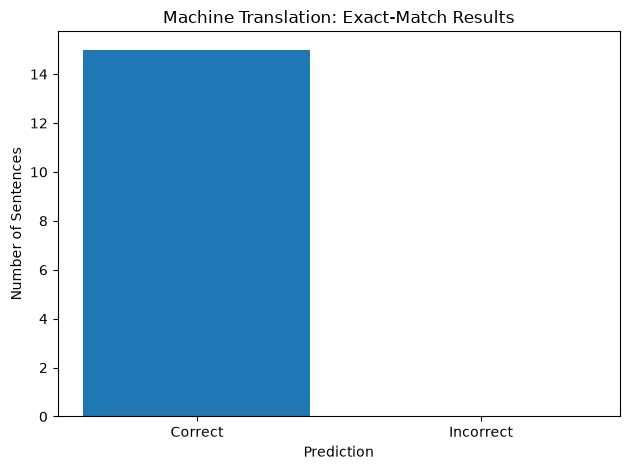

In [10]:
import matplotlib.pyplot as plt

correct_count = sum(
    df["Predicted_Hindi"] == df["Hindi"]
)

incorrect_count = len(df) - correct_count

plt.bar(
    ["Correct", "Incorrect"],
    [correct_count, incorrect_count]
)

plt.title("Machine Translation: Exact-Match Results")
plt.xlabel("Prediction")
plt.ylabel("Number of Sentences")
plt.tight_layout()
plt.show()